# Optimización de Portafolios — ML: XGBoost y Random Forest

## Parte 2: Capa de Machine Learning

**Jacqueline Espinosa** — Lic. en Actuaría, FCFM UANL
Octubre 2026

---

En la Parte 1 usé Markowitz clásico: calculas el rendimiento promedio histórico de cada acción, armas la matriz de covarianzas y optimizas. El problema es que asume que el pasado se va a repetir tal cual.

Aquí la idea es reemplazar ese "promedio histórico" con una predicción de Machine Learning. En vez de decir "NVDA promedió 77% anual los últimos 4 años, entonces va a seguir así", entreno un modelo que analiza patrones técnicos (momentum, volatilidad, RSI, etc.) y hace una predicción más informada.

**Plan:**

| Parte | Qué hace | |
|-------|----------|-|
| 1 — Markowitz | Optimización clásica media-varianza | listo |
| 2 — ML | XGBoost / Random Forest para predecir rendimientos | (este notebook) |
| 3 — DL | LSTM para series de tiempo | pendiente |
| 4 — Backtesting | Comparar Markowitz puro vs ML vs DL | pendiente |

---
## Contexto teórico

### Random Forest

Un Random Forest es un conjunto de árboles de decisión. Cada árbol se entrena con una muestra aleatoria de los datos y un subconjunto aleatorio de features. Al final se promedian las predicciones de todos los árboles.

La ventaja es que reduce el overfitting: un solo árbol se puede memorizar los datos de entrenamiento, pero al promediar muchos árboles con datos distintos, ese ruido se cancela y queda la señal real.

En nuestro caso, cada árbol va a aprender reglas como: "si el RSI está abajo de 30 y el momentum a 10 días es negativo, el rendimiento futuro tiende a ser positivo" (señal de reversión a la media).

### XGBoost (Extreme Gradient Boosting)

XGBoost también usa árboles, pero en vez de entrenarlos en paralelo como Random Forest, los entrena en secuencia. Cada árbol nuevo se enfoca en corregir los errores que dejaron los anteriores.

Es como si el primer árbol hiciera una predicción general, el segundo corrigiera donde el primero falló más, el tercero corrigiera al segundo, etc. Al final sumas todas las correcciones.

XGBoost suele ser más preciso que Random Forest pero más propenso a overfitting si no lo regularizas bien. Por eso vamos a usar ambos y comparar.

### ¿Qué predecimos?

El target es el rendimiento a 21 días hábiles (aprox. 1 mes). ¿Por qué no a 1 día? Porque los rendimientos diarios son muy ruidosos — prácticamente aleatorios. A 21 días hay más señal y se alinea con una frecuencia de rebalanceo mensual realista.

Como features uso indicadores técnicos: momentum (rendimientos pasados), RSI, MACD, Bandas de Bollinger, promedios móviles y volatilidad reciente. Son los mismos que usa un analista técnico, pero procesados por un modelo estadístico en vez de a ojo.

---
## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# XGBoost — si no lo tienes: pip install xgboost
try:
    from xgboost import XGBRegressor
    print("xgboost listo")
except ImportError:
    raise ImportError("Falta xgboost. Corre en la terminal: pip install xgboost")

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12

xgboost listo


## 2. Datos

Mismas 10 acciones y periodo que la Parte 1. Lo descargo de nuevo para que este notebook se pueda correr sin depender del otro.

In [2]:
TICKERS = ['AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'KO', 'AMZN', 'NVDA', 'CAT', 'PG']
BENCHMARK = 'SPY'
START = '2020-01-01'
END   = '2024-12-31'
RISK_FREE_RATE = 0.05
TRADING_DAYS = 252
HORIZON = 21   # dias habiles del target (aprox. 1 mes)

all_tickers = TICKERS + [BENCHMARK]
data = yf.download(all_tickers, start=START, end=END, auto_adjust=True)

if isinstance(data.columns, pd.MultiIndex):
    prices = data['Close'][all_tickers]
else:
    prices = data[all_tickers]

failed = prices.columns[prices.isna().all()]
if len(failed) > 0:
    print(f"No se pudieron descargar: {list(failed)}")
    print("Vuelve a correr esta celda o reinicia el kernel.")

prices = prices.dropna()
print(f"Periodo: {prices.index[0].date()} a {prices.index[-1].date()}")
print(f"Dias de trading: {len(prices)}")

curl_cffi not available; falling back to requests without browser TLS impersonation. Yahoo Finance may rate-limit or block this client. Install curl_cffi (>=0.15) for the supported configuration.
[*********************100%***********************]  11 of 11 completed

Periodo: 2020-01-02 a 2024-12-30
Dias de trading: 1257


## 3. Feature Engineering

Esta es la parte clave del ML. Los features (variables predictoras) determinan qué tan bien puede predecir el modelo. Uso indicadores técnicos estándar:

- **Rendimientos pasados** (1, 5, 10, 21 días) — capturan momentum. Si una acción subió las últimas semanas, ¿va a seguir o va a corregir?
- **Promedios móviles** (SMA 10, 20, 50 días relativo al precio) — si el precio está por encima de su promedio móvil, tendencia alcista.
- **RSI 14 días** — oscila entre 0 y 100. Arriba de 70 indica sobrecompra, abajo de 30 sobreventa.
- **MACD** — diferencia entre EMAs de 12 y 26 días. Cuando cruza su línea señal puede indicar cambio de tendencia.
- **Bollinger %B** — dónde está el precio dentro de las Bandas de Bollinger. Cerca de 0 = banda inferior, cerca de 1 = banda superior.
- **Volatilidad reciente** (10 y 21 días) — la volatilidad tiende a agruparse (volatility clustering), la volatilidad pasada es buen predictor de la futura.

Normalizo los indicadores que dependen de la escala del precio (como MACD) dividiéndolos entre el precio, para que el modelo pueda comparar acciones de distintos niveles de precio.

In [3]:
def compute_features(close):
    """Calcula features tecnicos para una serie de precios."""
    df = pd.DataFrame(index=close.index)
    ret_1d = close.pct_change()

    # --- Momentum (rendimientos pasados) ---
    df['ret_1d']  = ret_1d
    df['ret_5d']  = close.pct_change(5)
    df['ret_10d'] = close.pct_change(10)
    df['ret_21d'] = close.pct_change(21)

    # --- Promedios moviles vs precio ---
    df['sma10_ratio'] = close / close.rolling(10).mean()
    df['sma20_ratio'] = close / close.rolling(20).mean()
    df['sma50_ratio'] = close / close.rolling(50).mean()

    # --- RSI 14 dias ---
    delta = close.diff()
    gain  = delta.clip(lower=0).rolling(14).mean()
    loss  = (-delta.clip(upper=0)).rolling(14).mean()
    rs = gain / loss
    df['rsi_14'] = 100 - (100 / (1 + rs))

    # --- MACD (normalizado) ---
    ema12 = close.ewm(span=12, adjust=False).mean()
    ema26 = close.ewm(span=26, adjust=False).mean()
    macd_line   = ema12 - ema26
    signal_line = macd_line.ewm(span=9, adjust=False).mean()
    df['macd_diff'] = (macd_line - signal_line) / close

    # --- Bollinger %B ---
    sma20 = close.rolling(20).mean()
    std20 = close.rolling(20).std()
    upper = sma20 + 2 * std20
    lower = sma20 - 2 * std20
    df['bb_pct'] = (close - lower) / (upper - lower)

    # --- Volatilidad reciente ---
    df['vol_10d'] = ret_1d.rolling(10).std()
    df['vol_21d'] = ret_1d.rolling(21).std()

    return df

FEATURE_COLS = [
    'ret_1d', 'ret_5d', 'ret_10d', 'ret_21d',
    'sma10_ratio', 'sma20_ratio', 'sma50_ratio',
    'rsi_14', 'macd_diff', 'bb_pct',
    'vol_10d', 'vol_21d'
]
print(f"Features por accion: {len(FEATURE_COLS)}")

Features por accion: 12


Ahora calculo los features y el target (rendimiento a 21 días hacia adelante) para cada acción.

In [4]:
stock_data = {}

for ticker in TICKERS:
    feats = compute_features(prices[ticker])
    # Target: rendimiento a 21 dias hacia adelante
    feats['target'] = prices[ticker].shift(-HORIZON) / prices[ticker] - 1
    feats = feats.dropna()
    stock_data[ticker] = feats

print(f"{'Ticker':>8s}  {'Obs':>5s}   {'Desde':>12s}  {'Hasta':>12s}")
print("-" * 48)
for tk, df in stock_data.items():
    print(f"{tk:>8s}  {len(df):>5d}   {str(df.index[0].date()):>12s}  {str(df.index[-1].date()):>12s}")

  Ticker    Obs          Desde         Hasta
------------------------------------------------
    AAPL   1187     2020-03-13    2024-11-27
    MSFT   1187     2020-03-13    2024-11-27
     JPM   1187     2020-03-13    2024-11-27
     JNJ   1187     2020-03-13    2024-11-27
     XOM   1187     2020-03-13    2024-11-27
      KO   1187     2020-03-13    2024-11-27
    AMZN   1187     2020-03-13    2024-11-27
    NVDA   1187     2020-03-13    2024-11-27
     CAT   1187     2020-03-13    2024-11-27
      PG   1187     2020-03-13    2024-11-27


Se pierden las primeras ~50 filas por las ventanas rolling (la SMA de 50 días necesita 50 observaciones previas) y las últimas 21 filas porque el target mira 21 días hacia adelante. Es normal.

## 4. Train / Test Split

Separo en entrenamiento (2020-2023) y prueba (2024). Esto es fundamental: si evaluara el modelo con los mismos datos que usé para entrenarlo, los resultados se verían artificialmente bien (overfitting).

En series de tiempo NO puedo hacer un split aleatorio como en ML de tablas, porque perdería el orden temporal. Siempre entreno con datos del pasado y pruebo en el futuro.

In [5]:
SPLIT_DATE = '2024-01-01'

train_sets = {}
test_sets  = {}

for ticker in TICKERS:
    df = stock_data[ticker]
    train_sets[ticker] = df[df.index < SPLIT_DATE]
    test_sets[ticker]  = df[df.index >= SPLIT_DATE]

print(f"{'Ticker':>8s}  {'Train':>6s}  {'Test':>6s}")
print("-" * 26)
for tk in TICKERS:
    print(f"{tk:>8s}  {len(train_sets[tk]):>6d}  {len(test_sets[tk]):>6d}")

  Ticker   Train    Test
--------------------------
    AAPL     957     230
    MSFT     957     230
     JPM     957     230
     JNJ     957     230
     XOM     957     230
      KO     957     230
    AMZN     957     230
    NVDA     957     230
     CAT     957     230
      PG     957     230


## 5. Entrenamiento

Entreno un modelo por acción: 10 Random Forests + 10 XGBoosts = 20 modelos. Cada uno aprende a predecir el rendimiento a 21 días de su acción usando los 12 features técnicos.

Los hiperparámetros los pongo moderados para evitar overfitting:
- `n_estimators=200` — 200 árboles. Suficientes para estabilidad sin ser excesivo.
- `max_depth` limitado — no dejo que los árboles crezcan tanto que memoricen el ruido.
- `learning_rate=0.05` en XGB — pasos chicos para que aprenda gradualmente.
- Regularización en XGB (`reg_alpha`, `reg_lambda`) — penaliza modelos demasiado complejos.

In [6]:
rf_models  = {}
xgb_models = {}

for ticker in TICKERS:
    X_tr = train_sets[ticker][FEATURE_COLS]
    y_tr = train_sets[ticker]['target']

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_tr, y_tr)
    rf_models[ticker] = rf

    # XGBoost
    xgb = XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        verbosity=0
    )
    xgb.fit(X_tr, y_tr)
    xgb_models[ticker] = xgb

print("Entrenados: 10 Random Forest + 10 XGBoost")

Entrenados: 10 Random Forest + 10 XGBoost


## 6. Evaluación en datos de prueba

Evalúo en 2024 (out-of-sample) con tres métricas:

- **R²** — qué proporción de la varianza del rendimiento explica el modelo. En finanzas un R² de 0.02-0.10 ya se considera útil; los mercados son muy ruidosos.
- **MAE** — error absoluto promedio. Qué tanto se equivoca en magnitud.
- **Accuracy direccional** — porcentaje de veces que acierta si el rendimiento va a ser positivo o negativo. Arriba de 50% = mejor que un volado.

In [7]:
eval_rows = []

for ticker in TICKERS:
    X_te = test_sets[ticker][FEATURE_COLS]
    y_te = test_sets[ticker]['target']

    p_rf  = rf_models[ticker].predict(X_te)
    p_xgb = xgb_models[ticker].predict(X_te)

    eval_rows.append({
        'Ticker': ticker,
        'R2_RF':  r2_score(y_te, p_rf),
        'MAE_RF': mean_absolute_error(y_te, p_rf),
        'Dir_RF': np.mean(np.sign(p_rf) == np.sign(y_te)) * 100,
        'R2_XGB':  r2_score(y_te, p_xgb),
        'MAE_XGB': mean_absolute_error(y_te, p_xgb),
        'Dir_XGB': np.mean(np.sign(p_xgb) == np.sign(y_te)) * 100,
    })

eval_df = pd.DataFrame(eval_rows).set_index('Ticker')

In [8]:
print("=== Random Forest ===")
rf_view = eval_df[['R2_RF', 'MAE_RF', 'Dir_RF']].copy()
rf_view.columns = ['R²', 'MAE', 'Dir Acc (%)']
print(rf_view.round(4).to_string())
print(f"\nPromedio R²:       {eval_df['R2_RF'].mean():.4f}")
print(f"Promedio Dir Acc:  {eval_df['Dir_RF'].mean():.1f}%")

print("\n=== XGBoost ===")
xgb_view = eval_df[['R2_XGB', 'MAE_XGB', 'Dir_XGB']].copy()
xgb_view.columns = ['R²', 'MAE', 'Dir Acc (%)']
print(xgb_view.round(4).to_string())
print(f"\nPromedio R²:       {eval_df['R2_XGB'].mean():.4f}")
print(f"Promedio Dir Acc:  {eval_df['Dir_XGB'].mean():.1f}%")

=== Random Forest ===
            R²     MAE  Dir Acc (%)
Ticker                             
AAPL   -0.1874  0.0613      60.0000
MSFT   -0.1532  0.0414      60.8696
JPM    -0.3312  0.0485      63.4783
JNJ    -0.2119  0.0385      47.3913
XOM    -0.4886  0.0534      58.6957
KO     -0.3623  0.0398      38.6957
AMZN   -0.3211  0.0601      54.7826
NVDA   -0.1248  0.1348      72.1739
CAT    -0.2504  0.0615      53.9130
PG     -0.3286  0.0318      50.4348

Promedio R²:       -0.2759
Promedio Dir Acc:  56.0%

=== XGBoost ===
            R²     MAE  Dir Acc (%)
Ticker                             
AAPL   -0.5550  0.0697      50.4348
MSFT   -0.3504  0.0463      60.8696
JPM    -0.6533  0.0531      58.2609
JNJ    -0.3511  0.0403      50.0000
XOM    -0.6925  0.0588      59.5652
KO     -0.4811  0.0416      42.6087
AMZN   -0.6809  0.0683      58.2609
NVDA   -0.1647  0.1384      67.8261
CAT    -0.4326  0.0662      47.8261
PG     -0.7994  0.0368      49.1304

Promedio R²:       -0.5161
Promedio Dir Acc

Un R² bajo no significa que el modelo sea inútil. En predicción de rendimientos financieros, los mejores hedge funds del mundo trabajan con R² muy chicos. Lo que importa es que las predicciones, aunque imprecisas en magnitud, acierten la dirección más del 50% del tiempo y sean suficientemente diferentes del promedio histórico para agregar valor al portafolio.

### Feature importance

¿Cuáles features contribuyen más a las predicciones? Random Forest calcula la importancia de cada feature midiendo cuánto reduce el error de predicción en promedio a lo largo de todos los árboles. Promedio la importancia de los 10 modelos (uno por acción).

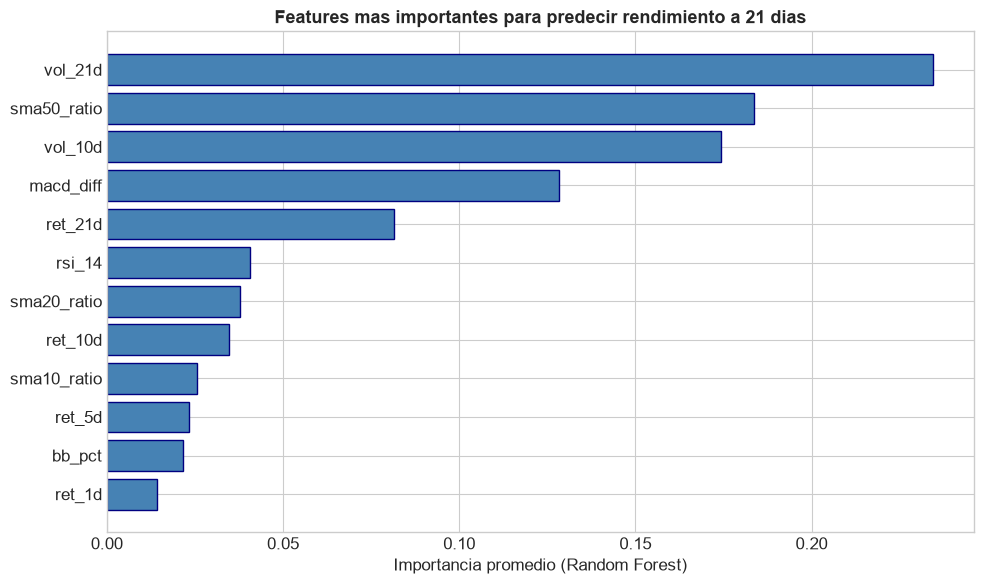

In [9]:
imp_avg = np.zeros(len(FEATURE_COLS))
for ticker in TICKERS:
    imp_avg += rf_models[ticker].feature_importances_
imp_avg /= len(TICKERS)

imp_df = pd.DataFrame({'Feature': FEATURE_COLS, 'Importancia': imp_avg})
imp_df = imp_df.sort_values('Importancia', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp_df['Feature'], imp_df['Importancia'], color='steelblue', edgecolor='navy')
ax.set_xlabel('Importancia promedio (Random Forest)')
ax.set_title('Features mas importantes para predecir rendimiento a 21 dias',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Generalmente los rendimientos pasados y la volatilidad reciente salen como los más importantes. Tiene sentido: el momentum y el volatility clustering son de los pocos patrones que se mantienen consistentes en mercados financieros. El RSI y Bollinger capturan señales de reversión a la media que complementan al momentum.

## 7. Actual vs predicho

Para visualizar qué tan bien predicen los modelos, grafico el rendimiento real contra el predicho para dos acciones: una de alto rendimiento (NVDA) y una más estable (JPM). Si el modelo fuera perfecto, todos los puntos caerían sobre la línea roja.

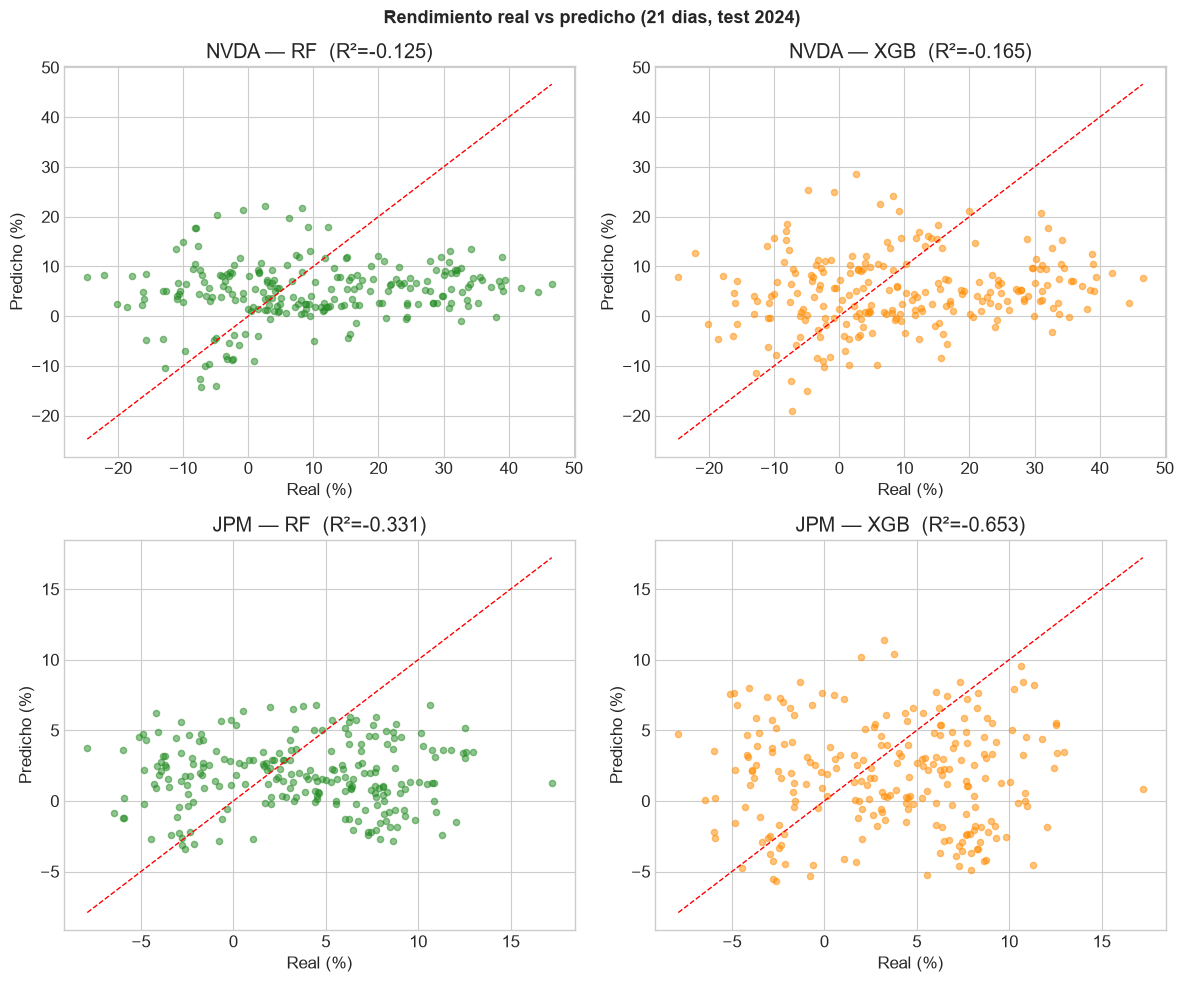

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, ticker in enumerate(['NVDA', 'JPM']):
    X_te = test_sets[ticker][FEATURE_COLS]
    y_te = test_sets[ticker]['target']
    p_rf  = rf_models[ticker].predict(X_te)
    p_xgb = xgb_models[ticker].predict(X_te)

    # Random Forest
    ax = axes[i, 0]
    ax.scatter(y_te*100, p_rf*100, alpha=0.5, s=20, c='forestgreen')
    lims = [min(y_te.min(), p_rf.min())*100, max(y_te.max(), p_rf.max())*100]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel('Real (%)')
    ax.set_ylabel('Predicho (%)')
    ax.set_title(f'{ticker} — RF  (R²={r2_score(y_te, p_rf):.3f})')

    # XGBoost
    ax = axes[i, 1]
    ax.scatter(y_te*100, p_xgb*100, alpha=0.5, s=20, c='darkorange')
    lims = [min(y_te.min(), p_xgb.min())*100, max(y_te.max(), p_xgb.max())*100]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel('Real (%)')
    ax.set_ylabel('Predicho (%)')
    ax.set_title(f'{ticker} — XGB  (R²={r2_score(y_te, p_xgb):.3f})')

plt.suptitle('Rendimiento real vs predicho (21 dias, test 2024)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. De predicciones a portafolio

Ahora conecto el ML con Markowitz. La idea:

1. Para cada acción, promedio sus predicciones sobre el test set y anualizo. Eso me da el "rendimiento esperado según ML".
2. La matriz de covarianzas la calculo con datos del training set (2020-2023), igual para todos.
3. Meto esos rendimientos esperados al mismo optimizador de la Parte 1 (maximizar Sharpe con SLSQP).

Comparo tres portafolios:
- **Histórico** — rendimiento esperado = promedio del training set (Markowitz puro)
- **RF** — rendimiento esperado = predicción de Random Forest
- **XGB** — rendimiento esperado = predicción de XGBoost

In [11]:
# Rendimientos esperados segun cada metodo
pred_ret_rf  = {}
pred_ret_xgb = {}

for ticker in TICKERS:
    X_te = test_sets[ticker][FEATURE_COLS]
    p_rf  = rf_models[ticker].predict(X_te)
    p_xgb = xgb_models[ticker].predict(X_te)
    # Anualizar: rendimiento a 21 dias * (252/21)
    pred_ret_rf[ticker]  = p_rf.mean()  * (TRADING_DAYS / HORIZON)
    pred_ret_xgb[ticker] = p_xgb.mean() * (TRADING_DAYS / HORIZON)

er_rf  = np.array([pred_ret_rf[tk]  for tk in TICKERS])
er_xgb = np.array([pred_ret_xgb[tk] for tk in TICKERS])

# Historico: promedio SOLO del training set (sin ver 2024)
train_daily = prices[TICKERS].loc[:SPLIT_DATE].pct_change().dropna()
er_hist = (train_daily.mean() * TRADING_DAYS).values

# Covarianza (training set para todos)
cov_mat = (train_daily.cov() * TRADING_DAYS).values

comp = pd.DataFrame({
    'Historico (%)': er_hist * 100,
    'RF (%)':        er_rf  * 100,
    'XGB (%)':       er_xgb * 100,
}, index=TICKERS).round(2)

print("Rendimientos esperados anualizados:")
comp

Rendimientos esperados anualizados:


,Historico (%),RF (%),XGB (%)
AAPL,29.90,37.29,46.950001
MSFT,27.58,41.29,46.930000
JPM,13.62,21.47,21.090000
JNJ,6.60,3.55,4.100000
XOM,20.79,27.90,28.100000
KO,7.38,-5.10,-2.940000
AMZN,18.90,6.46,3.790000
NVDA,67.65,58.13,57.900002
CAT,25.06,23.20,21.290001
PG,9.24,7.83,7.840000


Las predicciones de ML suelen ser más moderadas que el promedio histórico. Esto es porque los modelos captan señales de reversión a la media y no simplemente extrapolan tendencias pasadas. Una acción que subió mucho puede tener un RSI alto (sobrecompra), lo que le baja la predicción.

## 9. Optimización

Mismo optimizador que la Parte 1. Cambio solo el vector de rendimientos esperados.

In [12]:
def portfolio_performance(w, er, cov):
    ret = np.dot(w, er)
    vol = np.sqrt(w @ cov @ w)
    sharpe = (ret - RISK_FREE_RATE) / vol
    return ret, vol, sharpe

def neg_sharpe(w, er, cov):
    return -(np.dot(w, er) - RISK_FREE_RATE) / np.sqrt(w @ cov @ w)

n = len(TICKERS)
x0   = np.ones(n) / n
cons = {'type': 'eq', 'fun': lambda w: w.sum() - 1}
bnds = tuple((0, 1) for _ in range(n))

opt = {}
for label, er in [('Historico', er_hist), ('RF', er_rf), ('XGB', er_xgb)]:
    res = minimize(neg_sharpe, x0, args=(er, cov_mat),
                   method='SLSQP', bounds=bnds, constraints=cons)
    w = res.x
    r, v, s = portfolio_performance(w, er, cov_mat)
    opt[label] = {'w': w, 'ret': r, 'vol': v, 'sharpe': s}

    print(f"--- {label} ---")
    print(f"  Rendimiento esperado: {r*100:.2f}%")
    print(f"  Volatilidad:          {v*100:.2f}%")
    print(f"  Sharpe:               {s:.4f}")
    nz = w > 0.001
    for tk, wt in zip(np.array(TICKERS)[nz], w[nz]):
        print(f"    {tk:6s}: {wt*100:.1f}%")
    print()

--- Historico ---
  Rendimiento esperado: 55.92%
  Volatilidad:          43.31%
  Sharpe:               1.1759
    XOM   : 7.5%
    NVDA  : 73.2%
    CAT   : 19.3%

--- RF ---
  Rendimiento esperado: 40.74%
  Volatilidad:          30.16%
  Sharpe:               1.1849
    AAPL  : 5.8%
    MSFT  : 56.6%
    XOM   : 22.0%
    NVDA  : 15.6%

--- XGB ---
  Rendimiento esperado: 44.44%
  Volatilidad:          28.92%
  Sharpe:               1.3640
    AAPL  : 36.2%
    MSFT  : 50.5%
    XOM   : 13.3%



## 10. Comparación de asignaciones

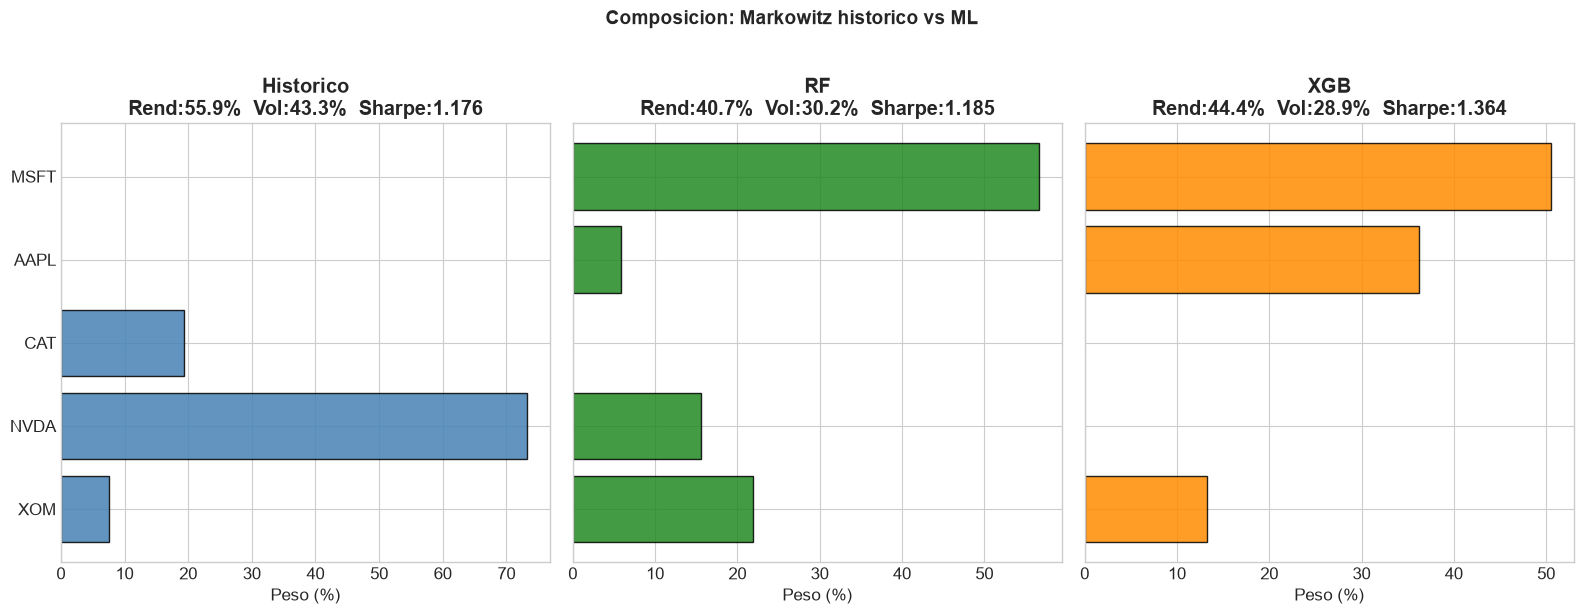

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

colors = {'Historico': 'steelblue', 'RF': 'forestgreen', 'XGB': 'darkorange'}

for ax, label in zip(axes, ['Historico', 'RF', 'XGB']):
    w = opt[label]['w']
    mask = w > 0.001
    ax.barh(np.array(TICKERS)[mask], w[mask]*100,
            color=colors[label], edgecolor='black', alpha=0.85)
    ax.set_xlabel('Peso (%)')
    r, v, s = opt[label]['ret'], opt[label]['vol'], opt[label]['sharpe']
    ax.set_title(f'{label}\nRend:{r*100:.1f}%  Vol:{v*100:.1f}%  Sharpe:{s:.3f}',
                 fontweight='bold')

plt.suptitle('Composicion: Markowitz historico vs ML',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Si el portafolio ML está más diversificado que el histórico, es señal de que las predicciones son más equilibradas — no depende tanto de una sola acción con rendimiento extremo en el pasado.

## 11. Backtest en 2024

La prueba real: ¿cómo se habrían comportado estos portafolios en 2024 con datos que los modelos NUNCA vieron durante el entrenamiento?

Uso pesos fijos durante todo el año (sin rebalanceo). Es un backtest simplificado — en la Parte 4 se hace el backtesting formal con rebalanceo periódico y métricas como drawdown máximo.

In [14]:
# Rendimientos diarios del test period
test_prices = prices[prices.index >= SPLIT_DATE]
test_daily  = test_prices[TICKERS].pct_change().dropna()
test_bench  = test_prices[BENCHMARK].pct_change().dropna()

# Alinear fechas
common = test_daily.index.intersection(test_bench.index)
test_daily = test_daily.loc[common]
test_bench = test_bench.loc[common]

# Rendimiento acumulado
cum = {}
for label in ['Historico', 'RF', 'XGB']:
    cum[label] = (1 + test_daily @ opt[label]['w']).cumprod()
cum['Equal-Weight'] = (1 + test_daily.mean(axis=1)).cumprod()
cum['SPY']          = (1 + test_bench).cumprod()

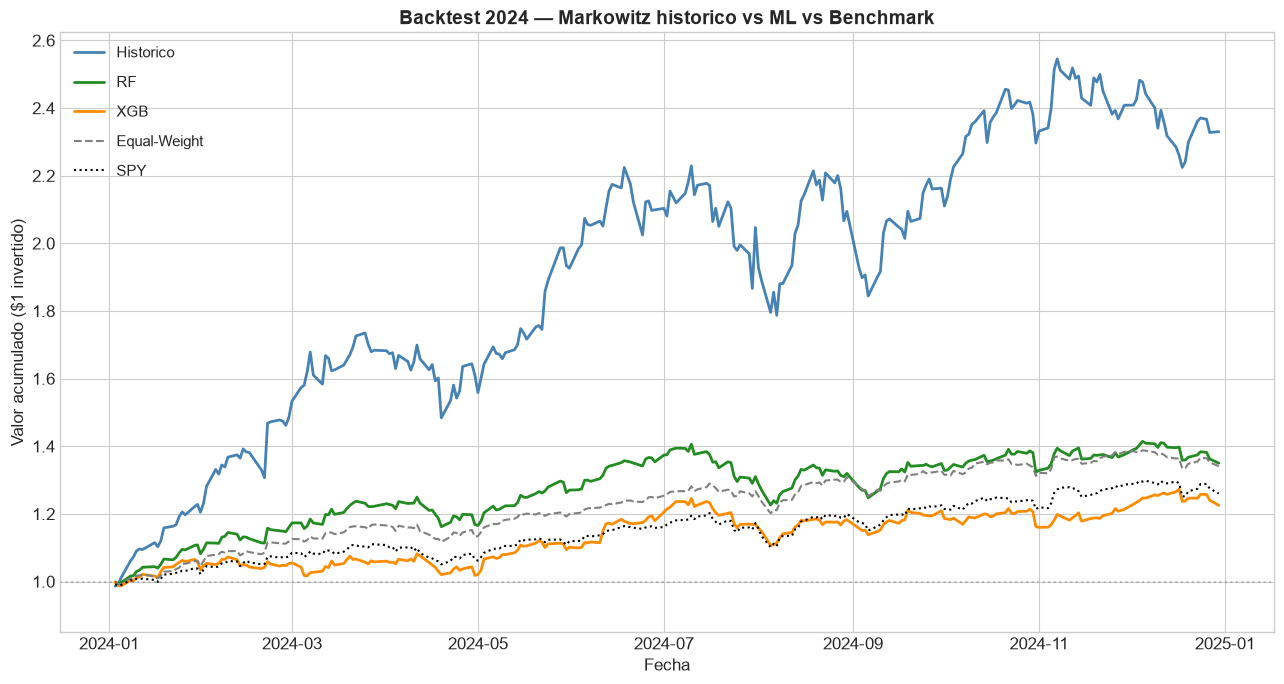

In [15]:
fig, ax = plt.subplots(figsize=(13, 7))

styles = {
    'Historico':    ('steelblue',  '-',  2.0),
    'RF':           ('forestgreen','-',  2.0),
    'XGB':          ('darkorange', '-',  2.0),
    'Equal-Weight': ('gray',       '--', 1.5),
    'SPY':          ('black',      ':',  1.5),
}

for label, (c, ls, lw) in styles.items():
    ax.plot(cum[label].index, cum[label].values, color=c, ls=ls, lw=lw, label=label)

ax.axhline(y=1, color='black', ls=':', alpha=0.2)
ax.set_xlabel('Fecha')
ax.set_ylabel('Valor acumulado ($1 invertido)')
ax.set_title('Backtest 2024 — Markowitz historico vs ML vs Benchmark',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, labelspacing=1.0)
ax.set_ylim(bottom=0.85)
plt.tight_layout()
plt.show()

In [16]:
print("Resultados 2024 (out-of-sample)")
print("=" * 58)
print(f"{'Portafolio':>14s}  {'Retorno':>9s}  {'Vol':>7s}  {'Sharpe':>7s}")
print("-" * 58)

for label in ['Historico', 'RF', 'XGB', 'Equal-Weight', 'SPY']:
    if label == 'SPY':
        dr = test_bench
    elif label == 'Equal-Weight':
        dr = test_daily.mean(axis=1)
    else:
        dr = test_daily @ opt[label]['w']

    ann_ret = dr.mean() * TRADING_DAYS
    ann_vol = dr.std()  * np.sqrt(TRADING_DAYS)
    sharpe  = (ann_ret - RISK_FREE_RATE) / ann_vol
    total   = cum[label].iloc[-1] - 1

    print(f"{label:>14s}  {total*100:>+8.2f}%  {ann_vol*100:>6.1f}%  {sharpe:>7.3f}")

Resultados 2024 (out-of-sample)
    Portafolio    Retorno      Vol   Sharpe
----------------------------------------------------------
     Historico   +133.03%    40.0%    2.207
            RF    +35.01%    17.4%    1.541
           XGB    +22.53%    15.7%    1.066
  Equal-Weight    +34.10%    11.7%    2.166
           SPY    +26.05%    12.6%    1.520


## 12. Resumen

In [17]:
resumen = pd.DataFrame({
    'Rend. Esperado (%)': [opt[l]['ret']*100 for l in ['Historico','RF','XGB']],
    'Volatilidad (%)':    [opt[l]['vol']*100 for l in ['Historico','RF','XGB']],
    'Sharpe (esperado)':  [opt[l]['sharpe']  for l in ['Historico','RF','XGB']],
}, index=['Markowitz Hist.', 'Random Forest', 'XGBoost'])

resumen.round(4)

,Rend. Esperado (%),Volatilidad (%),Sharpe (esperado)
Markowitz Hist.,55.9248,43.3074,1.1759
Random Forest,40.7377,30.1606,1.1849
XGBoost,44.4434,28.9174,1.3640


### Conclusiones

Los modelos de ML generan estimaciones de rendimiento distintas al promedio histórico, y eso se traduce en portafolios con composiciones diferentes:

1. **Predicciones más moderadas** — Los modelos no extrapolan rendimientos extremos del pasado. Si NVDA subió 77% anual promedio en 2020-2024, el modelo no asume que va a seguir así porque detecta señales técnicas que matizan la predicción.

2. **Diversificación** — Los portafolios ML tienden a distribuir mejor los pesos, lo cual reduce la dependencia de una sola acción.

3. **R² bajos pero útiles** — En finanzas un R² perfecto no existe. Lo relevante es que la accuracy direccional supere el 50% y que las predicciones capturen patrones que el promedio histórico ignora.

4. **Limitaciones** — Los features son puramente técnicos; no incluyen datos fundamentales (earnings, P/E, etc.) ni macroeconómicos (tasas, inflación). Agregar esos features podría mejorar las predicciones. Además, el backtest usa pesos fijos sin rebalanceo.

En la Parte 3 uso LSTM (redes neuronales recurrentes) que pueden capturar dependencias temporales más largas y no lineales. Y en la Parte 4 hago el backtesting formal comparando Markowitz vs RF vs XGB vs LSTM con rebalanceo mensual, drawdown máximo y otras métricas.